In [5]:
import osgeo
import rasterio
import rasterio.plot
import rioxarray
import xarray as xr
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
import matplotlib.patches as mpatches
import pandas as pd
import geopandas as gpd
import netCDF4
import h5netcdf
import dask
import rasterio.features as features

## Open data

In [23]:
path_tree_cover_density = 'C:/Users/minttu/Documents/Tree_cover/TCD2010_0.05deg.tif'

In [24]:
path_LC_Hansen = 'C:/Users/minttu/Documents/LC_300m_data/LCD-2000-0.05deg.tif'

In [25]:
TCD = rioxarray.open_rasterio(path_tree_cover_density)

In [26]:
LCD = rioxarray.open_rasterio(path_LC_Hansen)

## Plot tree cover density and land cover

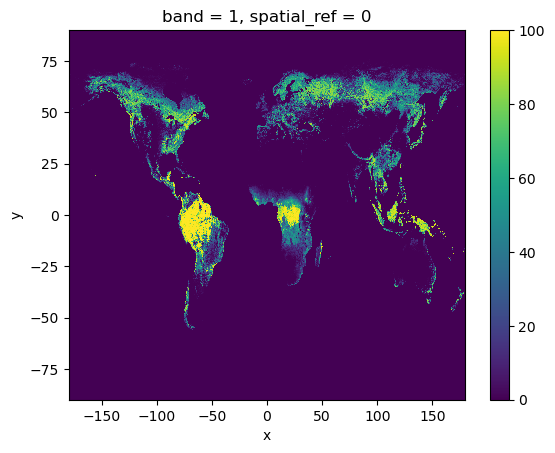

In [6]:
TCD.plot()

## Create LCD layer

All selected classes of the LC2000 data set are first extracted as binary masks per class, some of the land cover classes are area weighted depending on the percentage of tree cover as provided by the Land Cover CCI. 

In [ ]:
#LCD = LCHansen2000.where(LCHansen2000 != 30, 0.5)
#LCD = LCD.where(LCD != 110, 0.5)
#LCD = LCD.where(LCD != 150, 0.15)

In [7]:
#values_to_replace = [40, 50, 60, 61, 62, 70, 71, 72, 80, 81, 82, 90, 100, 120, 121, 122, 160, 170, 180]
#mask = LCD.isin(values_to_replace)
#LCD = LCD.where(~mask, 1)

In [8]:
#values_to_replace = [10, 11, 12, 20, 130, 140, 151, 152, 153, 190, 201, 202, 200, 210, 220]
#mask = LCD.isin(values_to_replace)
#LCD = LCD.where(~mask, False)

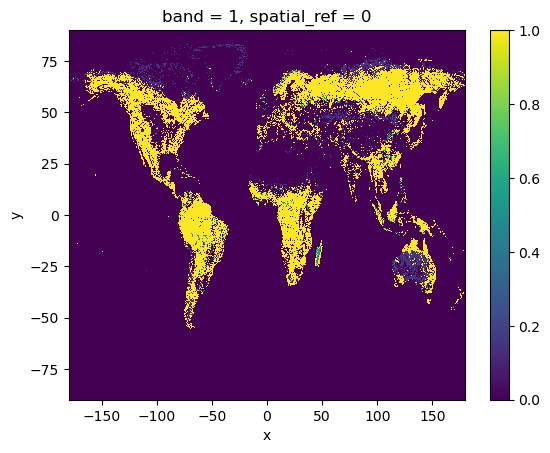

In [9]:
#LCD.plot()

In [9]:
#print(np.unique(LCHansen2000.values[~np.isnan(LCHansen2000.values)]))

[ 10.  11.  12.  20.  30.  40.  50.  60.  61.  62.  70.  71.  72.  80.
  81.  90. 100. 110. 120. 121. 122. 130. 140. 150. 151. 152. 153. 160.
 170. 180. 190. 200. 201. 202. 210. 220.]


In [11]:
#print(np.unique(LCD.values[~np.isnan(LCD.values)]))

[0.   0.15 0.5  1.  ]


## Show LCD

In [27]:
LCD

<xarray.DataArray (band: 1, y: 3600, x: 7200)> Size: 104MB
[25920000 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 29kB 89.97 89.92 89.88 ... -89.88 -89.93 -89.98
  * x            (x) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [35]:
print(np.unique(LCD.values[~np.isnan(LCD.values)]))

[0.         0.0015     0.003      ... 0.9999999  0.99999994 1.        ]


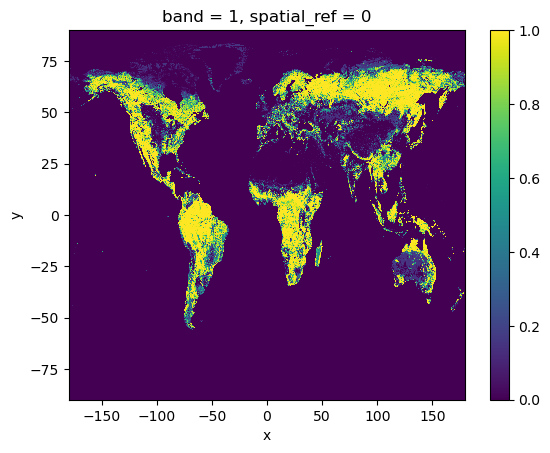

In [28]:
LCD.plot()

## Calculate transmissivity

In [29]:
e = 2.718281828459045235360287471352

In [30]:
t2 = 0.08 * e ** ((1-(TCD*LCD))*2.52572864)

In [31]:
# getting the original colormap using cm.get_cmap() function
orig_map=pyplot.cm.get_cmap('Greens')

# reversing the original colormap using reversed() function
reversed_map = orig_map.reversed()

C:\Users\minttu\AppData\Local\Temp\ipykernel_12344\3636168311.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  orig_map=pyplot.cm.get_cmap('Greens')


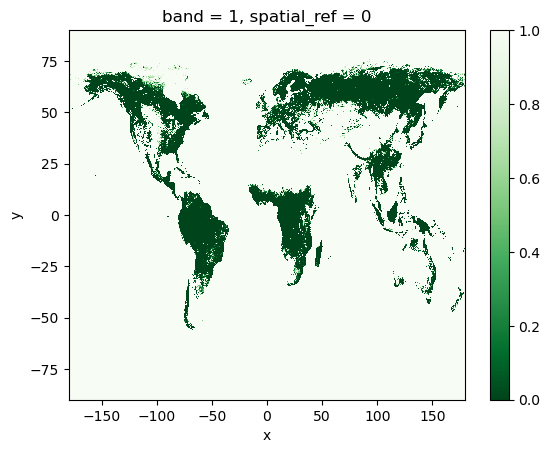

In [32]:
t2.plot(cmap=reversed_map)

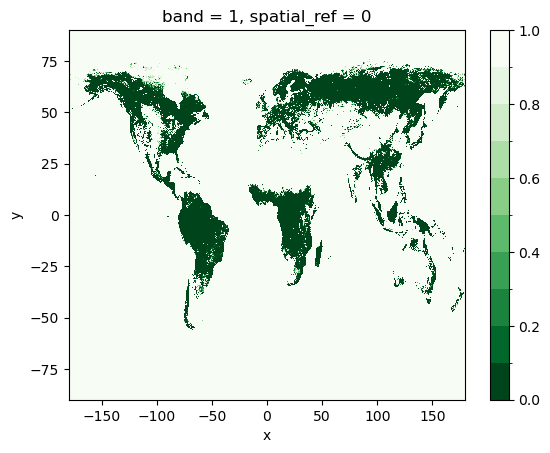

In [39]:
import numpy as np
import matplotlib.colors as mcolors

# Number of discrete steps
n_steps = 10

# Build a discretized version of your reversed_map
stepped_cmap = mcolors.ListedColormap(reversed_map(np.linspace(0, 1, n_steps)))

# Define the boundaries for each step across your data's actual range
vmin = np.nanmin(t2.values)
vmax = np.nanmax(t2.values)
bounds = np.linspace(vmin, vmax, n_steps + 1)
norm = mcolors.BoundaryNorm(bounds, stepped_cmap.N)

t2.plot(cmap=stepped_cmap, norm=norm)

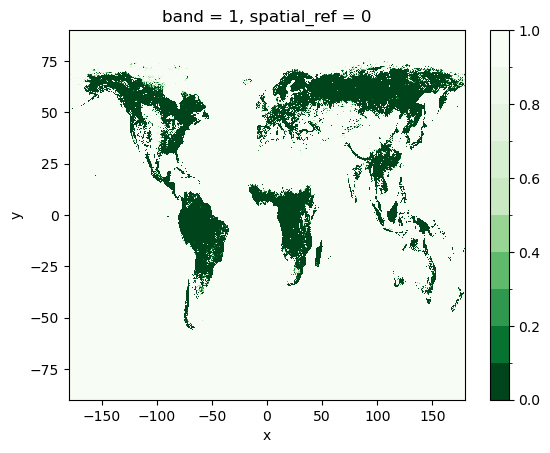

In [44]:
import numpy as np
import matplotlib.colors as mcolors

# Number of discrete steps
n_steps = 10

# --- Non-uniform color sampling ---
# Steps in the data's lower half (0-0.5) pull colors from a WIDE slice
# of the colormap (more variation, more dramatic gradient), while the
# upper half (0.5-1) gets compressed into the remaining range.
# Endpoints (0 and 1) stay untouched.

low_steps = n_steps // 2   # steps covering 0-0.5
high_steps = n_steps - low_steps  # steps covering 0.5-1

low_range_end = 0.75   # how much of the colormap's range low values use — higher = more dramatic/intense gradient
low_colors = reversed_map(np.linspace(0, low_range_end, low_steps, endpoint=False))
high_colors = reversed_map(np.linspace(low_range_end, 1, high_steps))

all_colors = np.vstack([low_colors, high_colors])
stepped_cmap = mcolors.ListedColormap(all_colors)

# Bounds stay evenly spaced across the actual data range, unchanged
vmin = np.nanmin(t2.values)
vmax = np.nanmax(t2.values)
bounds = np.linspace(vmin, vmax, n_steps + 1)
norm = mcolors.BoundaryNorm(bounds, stepped_cmap.N)

t2.plot(cmap=stepped_cmap, norm=norm)

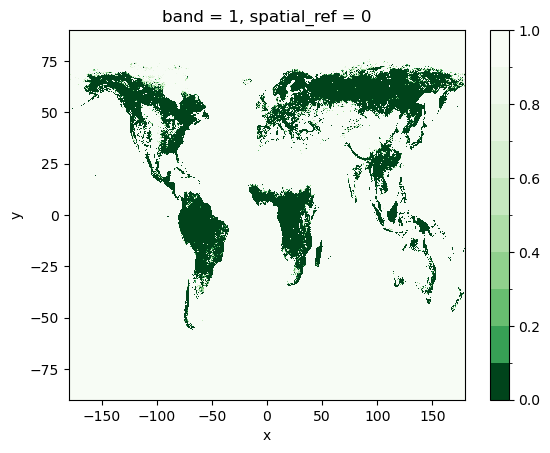

In [45]:
import numpy as np
import matplotlib.colors as mcolors

# Number of discrete steps
n_steps = 10

# --- Intensified gradient across the full range ---
# gamma < 1 spreads colors out more (more intense/dramatic gradient)
# gamma = 1 is the original, evenly-spaced gradient
# gamma > 1 would compress colors together (less dramatic)
# Endpoints (0 and 1) stay untouched either way.

gamma = 0.5  # lower = more intense/dramatic gradient overall

step_positions = np.linspace(0, 1, n_steps)
stretched_positions = step_positions ** gamma

all_colors = reversed_map(stretched_positions)
stepped_cmap = mcolors.ListedColormap(all_colors)

# Bounds stay evenly spaced across the actual data range, unchanged
vmin = np.nanmin(t2.values)
vmax = np.nanmax(t2.values)
bounds = np.linspace(vmin, vmax, n_steps + 1)
norm = mcolors.BoundaryNorm(bounds, stepped_cmap.N)

t2.plot(cmap=stepped_cmap, norm=norm)

In [33]:
print(np.unique(t2.values[~np.isnan(t2.values)]))

[0.0000000e+00 1.4012985e-45 2.8025969e-45 ... 9.9245137e-01 9.9621838e-01
 1.0000000e+00]


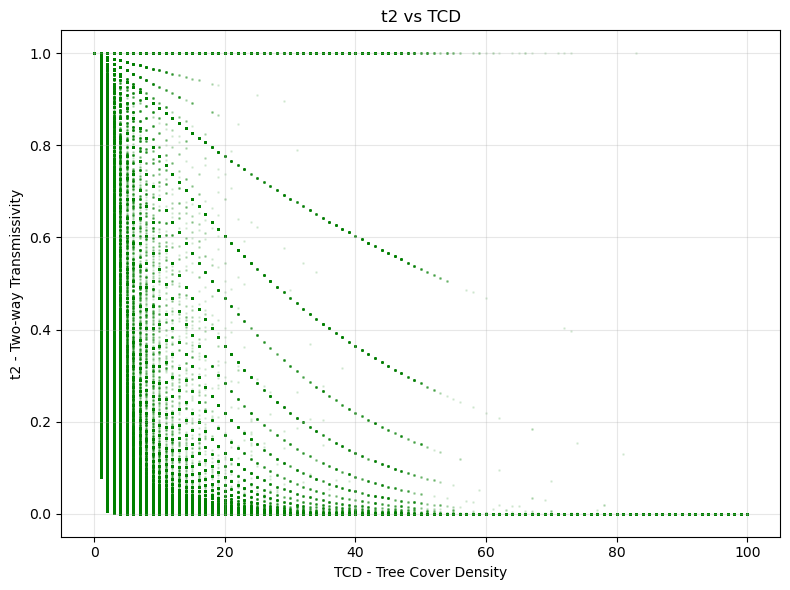

In [34]:
pyplot.figure(figsize=(8, 6))
pyplot.scatter(
    TCD.values.flatten(),
    t2.values.flatten(),
    alpha=0.1, s=1, color='green'
)
pyplot.xlabel('TCD - Tree Cover Density')
pyplot.ylabel('t2 - Two-way Transmissivity')
pyplot.title('t2 vs TCD')
pyplot.grid(True, alpha=0.3)
pyplot.tight_layout()
pyplot.show()

C:\Users\minttu\AppData\Local\Temp\ipykernel_12344\1170892389.py:33: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  pyplot.tight_layout()


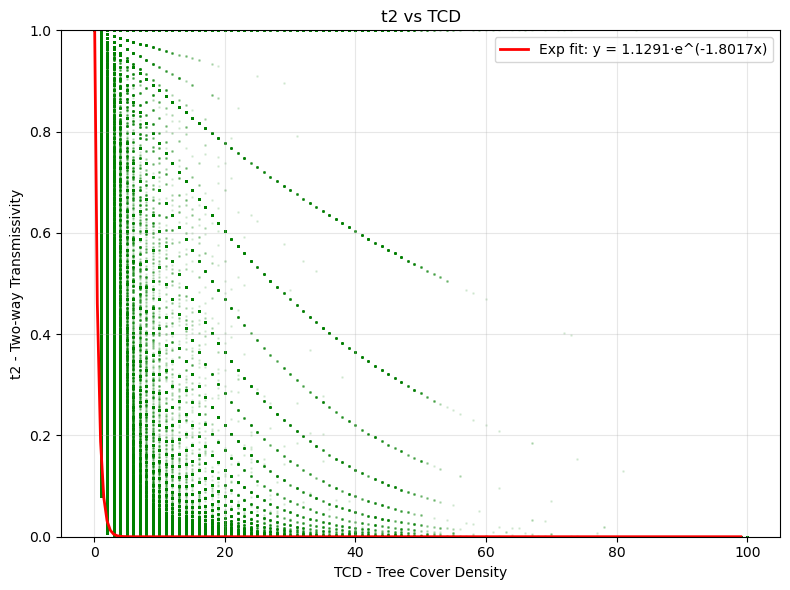

In [38]:
import numpy as np

x = TCD.values.flatten()
y = t2.values.flatten()

# Remove NaNs, and also remove y <= 0 since ln(y) is undefined there
mask = ~np.isnan(x) & ~np.isnan(y) & (y > 0)
x_clean = x[mask]
y_clean = y[mask]

# Fit an exponential curve: y = a*exp(b*x)
# Done by linearizing: ln(y) = ln(a) + b*x, then fitting a line to (x, ln(y))
b, log_a = np.polyfit(x_clean, np.log(y_clean), 1)
a = np.exp(log_a)

pyplot.figure(figsize=(8, 6))
pyplot.scatter(
    x, y,
    alpha=0.1, s=1, color='green'
)

# Plot the exponential best-fit line across the x range
x_line = np.linspace(x_clean.min(), x_clean.max(), 200)
y_line = a * np.exp(b * x_line)
pyplot.plot(x_line, y_line, color='red', linewidth=2, label=f'Exp fit: y = {a:.4f}·e^({b:.4f}x)')

pyplot.xlabel('TCD - Tree Cover Density')
pyplot.ylabel('t2 - Two-way Transmissivity')
pyplot.title('t2 vs TCD')
pyplot.grid(True, alpha=0.3)
pyplot.ylim(0, 1)
pyplot.legend()
pyplot.tight_layout()
pyplot.show()